<a href="https://colab.research.google.com/github/viniciusnobcosta/pos-fiap-data-analytics/blob/main/Analise_de_Dados_e_Storytelling_Fase1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Desafio: Análise de dados e Storytelling**

Importando as bases de dados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [ ]:
df_populacao = pd.read_excel("/content/Populacao_2013_2023.xlsx")
df_populacao.head()

,Município,uf,População 2013,População 2014,População 2015,População 2016,População 2017,População 2018,População 2019,População 2020,População 2021,População 2022,População 2023
0,ALTA FLORESTA D'OESTE,RO,25728,25652,25578,25506,25437,23167,22945,22728,22516,21494,21494
1,ARIQUEMES,RO,101269,102860,104401,105896,107345,106168,107863,109523,111148,96833,96833
2,CABIXI,RO,6495,6424,6355,6289,6224,5438,5312,5188,5067,5351,5351
3,CACOAL,RO,85863,86556,87226,87877,88507,84813,85359,85893,86416,86887,86887
4,CEREJEIRAS,RO,18041,18013,17986,17959,17934,16444,16323,16204,16088,15890,15890


In [ ]:
df_infeccoes = pd.read_excel("/content/Base de Dados Dengue.xlsx")
df_infeccoes.head()

,municipio,uf,data_infeccoes,qtd_infeccoes
0,ALTA FLORESTA D'OESTE,RO,2013-01-01,34
1,ALTA FLORESTA D'OESTE,RO,2013-02-01,44
2,ALTA FLORESTA D'OESTE,RO,2013-03-01,15
3,ALTA FLORESTA D'OESTE,RO,2013-04-01,4
4,ALTA FLORESTA D'OESTE,RO,2013-05-01,3


Juntando as duas bases

In [ ]:
# 1. Transformar o df_populacao para o formato longo (melt)
df_pop_long = df_populacao.melt(
    id_vars=['Município', 'uf'],
    var_name='ano_populacao',
    value_name='populacao'
)

# Extrair o ano como número inteiro da coluna 'ano_populacao' (ex: 'População 2013' -> 2013)
df_pop_long['ano'] = df_pop_long['ano_populacao'].str.extract(r'(\d+)').astype(int)

# Ajustar nomes de colunas de df_pop_long para facilitar o merge e remover coluna auxiliar
df_pop_long = df_pop_long.rename(columns={'Município': 'municipio'}).drop(columns=['ano_populacao'])

# Garantir que o nome das colunas de texto estejam padronizados (ex: sem espaços extras e em maiúsculas)
df_pop_long['municipio'] = df_pop_long['municipio'].str.strip().str.upper()
df_pop_long['uf'] = df_pop_long['uf'].str.strip().str.upper()

# 2. Preparar o df_infeccoes
df_infeccoes['data_infeccoes'] = pd.to_datetime(df_infeccoes['data_infeccoes'])
df_infeccoes['ano'] = df_infeccoes['data_infeccoes'].dt.year
df_infeccoes['municipio'] = df_infeccoes['municipio'].str.strip().str.upper()
df_infeccoes['uf'] = df_infeccoes['uf'].str.strip().str.upper()

# 3. Juntar as bases (merge) utilizando municipio, uf e ano
df_consolidado = pd.merge(
    df_infeccoes,
    df_pop_long,
    on=['municipio', 'uf', 'ano'],
    how='left'
)

df_consolidado.head()

,municipio,uf,data_infeccoes,qtd_infeccoes,ano,populacao
0,ALTA FLORESTA D'OESTE,RO,2013-01-01,34,2013,25728
1,ALTA FLORESTA D'OESTE,RO,2013-02-01,44,2013,25728
2,ALTA FLORESTA D'OESTE,RO,2013-03-01,15,2013,25728
3,ALTA FLORESTA D'OESTE,RO,2013-04-01,4,2013,25728
4,ALTA FLORESTA D'OESTE,RO,2013-05-01,3,2013,25728


Verificando os tipos de dados

In [ ]:
df_consolidado.shape

(728772, 6)

In [ ]:
df_consolidado.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 728772 entries, 0 to 728771
Data columns (total 6 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   municipio       728772 non-null  object        
 1   uf              728772 non-null  object        
 2   data_infeccoes  728772 non-null  datetime64[ns]
 3   qtd_infeccoes   728772 non-null  int64         
 4   ano             728772 non-null  int32         
 5   populacao       728772 non-null  int64         
dtypes: datetime64[ns](1), int32(1), int64(2), object(2)
memory usage: 30.6+ MB


In [ ]:
df_consolidado.duplicated().sum()

np.int64(0)

- A base possui 728.772 linhas e 6 colunas;
- Não existem linhas vazias;
- Todos os tipos de colunas já estão bem definidos;
- Não há linhas com duplicidade de valor.

Selecionando apenas os dados do RJ

In [ ]:
df_consolidado_rj = df_consolidado.query("uf == 'RJ'")
df_consolidado_rj.head()

,municipio,uf,data_infeccoes,qtd_infeccoes,ano,populacao
418440,ANGRA DOS REIS,RJ,2013-01-01,28,2013,181486
418441,ANGRA DOS REIS,RJ,2013-02-01,114,2013,181486
418442,ANGRA DOS REIS,RJ,2013-03-01,141,2013,181486
418443,ANGRA DOS REIS,RJ,2013-04-01,65,2013,181486
418444,ANGRA DOS REIS,RJ,2013-05-01,39,2013,181486


In [ ]:
df_consolidado_rj.shape

(12144, 6)

In [ ]:
df_consolidado_rj.municipio.unique()

array(['ANGRA DOS REIS', 'APERIBE', 'ARARUAMA', 'AREAL',
       'ARMACAO DOS BUZIOS', 'ARRAIAL DO CABO', 'BARRA DO PIRAI',
       'BARRA MANSA', 'BELFORD ROXO', 'BOM JARDIM',
       'BOM JESUS DO ITABAPOANA', 'CABO FRIO', 'CACHOEIRAS DE MACACU',
       'CAMBUCI', 'CARAPEBUS', 'COMENDADOR LEVY GASPARIAN',
       'CAMPOS DOS GOYTACAZES', 'CANTAGALO', 'CARDOSO MOREIRA', 'CARMO',
       'CASIMIRO DE ABREU', 'CONCEICAO DE MACABU', 'CORDEIRO',
       'DUAS BARRAS', 'DUQUE DE CAXIAS', 'ENGENHEIRO PAULO DE FRONTIN',
       'GUAPIMIRIM', 'IGUABA GRANDE', 'ITABORAI', 'ITAGUAI', 'ITALVA',
       'ITAOCARA', 'ITAPERUNA', 'ITATIAIA', 'JAPERI', 'LAJE DO MURIAE',
       'MACAE', 'MACUCO', 'MAGE', 'MANGARATIBA', 'MARICA', 'MENDES',
       'MESQUITA', 'MIGUEL PEREIRA', 'MIRACEMA', 'NATIVIDADE',
       'NILOPOLIS', 'NITEROI', 'NOVA FRIBURGO', 'NOVA IGUACU',
       'PARACAMBI', 'PARAIBA DO SUL', 'PARATY', 'PATY DO ALFERES',
       'PETROPOLIS', 'PINHEIRAL', 'PIRAI', 'PORCIUNCULA', 'PORTO REAL',
       'Q

Quantidade de casos confirmados de dengue

In [ ]:
print(f'Foram confirmados {df_consolidado_rj.qtd_infeccoes.sum()} casos de dengue no RJ dentro do período de 2013-2023')

Foram confirmados 109888 casos de dengue no RJ dentro do período de 2013-2023


In [ ]:
df_consolidado_rj.describe()

,data_infeccoes,qtd_infeccoes,ano,populacao
count,12144,12144.000000,12144.000000,1.214400e+04
mean,2018-06-16 13:27:16.363636224,9.048748,2018.000000,1.815749e+05
min,2013-01-01 00:00:00,0.000000,2013.000000,3.974000e+03
25%,2015-09-23 12:00:00,0.000000,2015.000000,1.812000e+04
50%,2018-06-16 00:00:00,0.000000,2018.000000,3.657300e+04
75%,2021-03-08 18:00:00,1.000000,2021.000000,1.330752e+05
max,2023-12-01 00:00:00,3027.000000,2023.000000,6.775561e+06
std,NaN,75.279793,3.162408,6.897969e+05


In [ ]:
df_rj_infeccoes_municipio = df_consolidado_rj.groupby('municipio')['qtd_infeccoes'].sum().reset_index().sort_values(by='qtd_infeccoes', ascending=False)
df_rj_infeccoes_municipio.head()

,municipio,qtd_infeccoes
67,RIO DE JANEIRO,34804
14,CAMPOS DOS GOYTACAZES,13835
48,NOVA FRIBURGO,6316
91,VOLTA REDONDA,5163
36,MACAE,3739


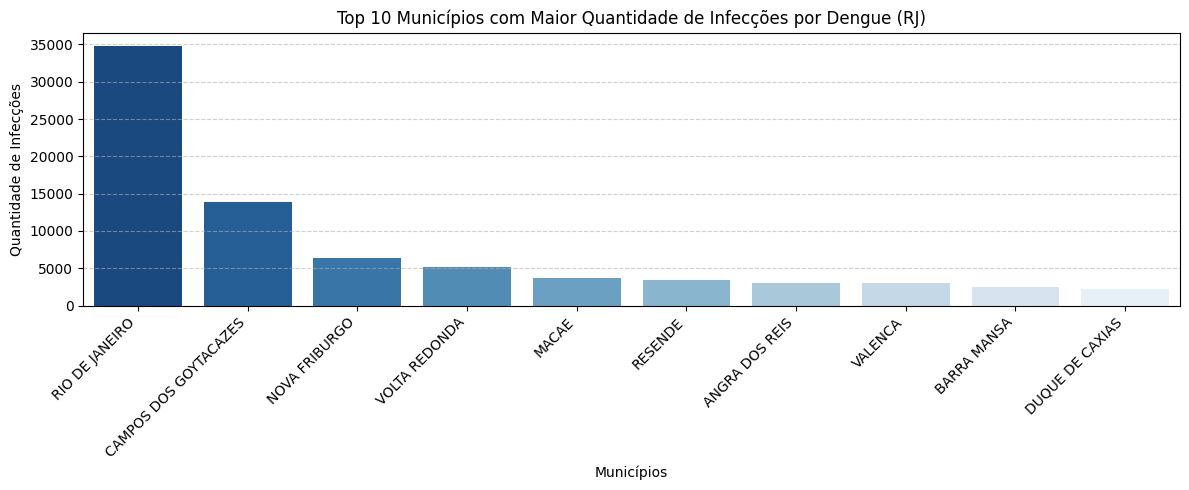

In [ ]:
# Criando gráfico para visualizar a quantidade de infecções apenas dos 10 municípios com mais casos
plt.figure(figsize=(12, 5))
sns.barplot(data=df_rj_infeccoes_municipio.head(10), x='municipio', y='qtd_infeccoes', palette='Blues_r')
plt.title('Top 10 Municípios com Maior Quantidade de Infecções por Dengue (RJ)')
plt.ylabel('Quantidade de Infecções')
plt.xlabel('Municípios')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Agrupar dados por município (soma das infecções e média da população do período)
df_rj_grafico = df_consolidado_rj.groupby('municipio').agg(
    qtd_infeccoes=('qtd_infeccoes', 'sum'),
    populacao_media=('populacao', 'mean')
).reset_index().sort_values(by='qtd_infeccoes', ascending=False)

# Criar figura com eixo secundário
fig = make_subplots(specs=[[{"secondary_y": True}]])

# Adicionar as colunas de Infecções (Eixo Principal)
fig.add_trace(
    go.Bar(
        x=df_rj_grafico['municipio'],
        y=df_rj_grafico['qtd_infeccoes'],
        name='Qtd Infecções',
        marker_color='royalblue'
    ),
    secondary_y=False
)

# Adicionar a linha de População Média (Eixo Secundário)
fig.add_trace(
    go.Scatter(
        x=df_rj_grafico['municipio'],
        y=df_rj_grafico['populacao_media'],
        name='População Média',
        mode='lines+markers',
        line=dict(color='firebrick', width=2)
    ),
    secondary_y=True
)

# Personalizar títulos e layout
fig.update_layout(
    title_text='Relação de Infecções por Dengue e População por Município (RJ)',
    xaxis_title='Município',
    hovermode='x unified',
    legend=dict(x=0.8, y=0.95)
)

fig.update_yaxes(title_text='Quantidade de Infecções', secondary_y=False)
fig.update_yaxes(title_text='População Média', secondary_y=True)

fig.show()

Taxa de infecção para cada município

In [ ]:
# Agrupando por município para somar as infecções e obter a população média do período
df_municipios = df_consolidado_rj.groupby('municipio').agg(
    qtd_infeccoes=('qtd_infeccoes', 'sum'),
    populacao=('populacao', 'mean')
).reset_index()

# Calculando a taxa de infecção (casos por habitante)
df_municipios['taxa_infeccao'] = df_municipios['qtd_infeccoes'] / df_municipios['populacao'] * 100

# Ordenando os municípios pela quantidade de infecções de forma decrescente
df_municipios = df_municipios.sort_values(by='qtd_infeccoes', ascending=False).reset_index(drop=True)

# Exibindo as primeiras linhas do novo DataFrame
df_municipios.head()

,municipio,qtd_infeccoes,populacao,taxa_infeccao
0,RIO DE JANEIRO,34804,6.521181e+06,0.533707
1,CAMPOS DOS GOYTACAZES,13835,4.930148e+05,2.806204
2,NOVA FRIBURGO,6316,1.879333e+05,3.360767
3,VOLTA REDONDA,5163,2.666055e+05,1.936570
4,MACAE,3739,2.455478e+05,1.522718


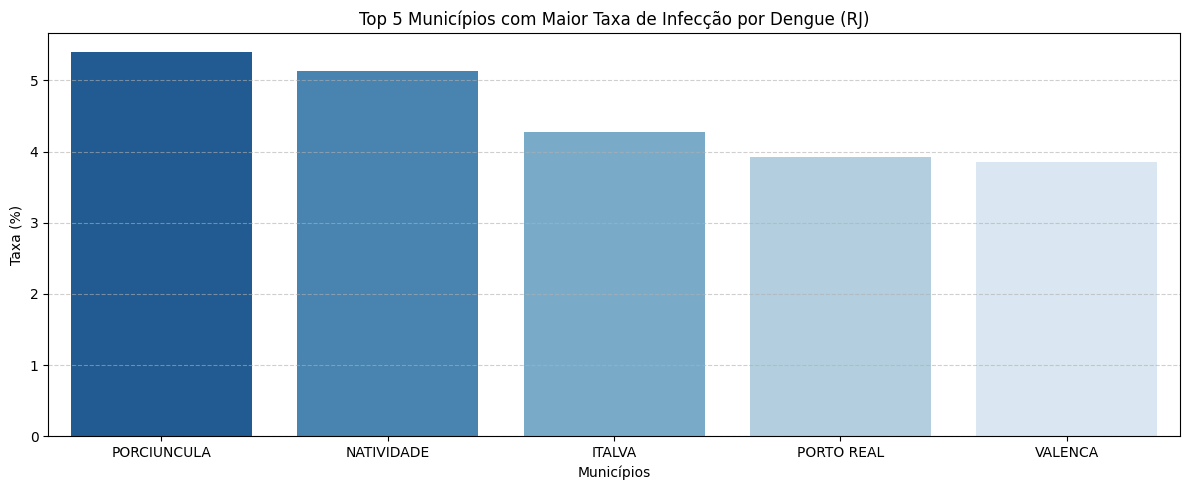

In [ ]:
plt.figure(figsize=(12, 5))
sns.barplot(
    data=df_municipios.sort_values(by='taxa_infeccao', ascending=False).head(),
    x='municipio',
    y='taxa_infeccao',
    hue='municipio',
    legend=False,
    palette='Blues_r'
)
plt.title('Top 5 Municípios com Maior Taxa de Infecção por Dengue (RJ)')
plt.ylabel('Taxa (%)')
plt.xlabel('Municípios')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

1. A ilusão do Rio de Janeiro como maior problema:

Olhando apenas para as barras azuis, o município do Rio de Janeiro parece ser o caso disparadamente mais alarmante, registrando mais de 34.800 infecções (quase o triplo do segundo colocado).
No entanto, quando olhamos para a linha vermelha, vemos que o Rio de Janeiro tem uma população média colossal de mais de 6,5 milhões de habitantes.

2. Os verdadeiros pontos críticos (Surtos Proporcionais):

Cidades como Campos dos Goytacazes (13.835 casos para ~493 mil hab.) e Nova Friburgo (6.316 casos para ~187 mil hab.) têm populações drasticamente menores que a capital, mas registraram um número proporcionalmente muito maior de infecções.
Nova Friburgo, por exemplo, tem uma taxa de infecção de 3,36%, enquanto a capital tem apenas 0,53%. Isso significa que a intensidade do surto e o risco de infecção por habitante foram muito maiores em Nova Friburgo do que na própria capital.

Visualizando por ano

In [ ]:
# Quantidade de casos por ano
infeccoes_ano = df_consolidado_rj.groupby('ano')['qtd_infeccoes'].sum().reset_index().sort_values(by='ano', ascending=True)
infeccoes_ano

,ano,qtd_infeccoes
0,2013,33398
1,2014,1483
2,2015,18730
3,2016,13721
4,2017,776
5,2018,1746
6,2019,3816
7,2020,1054
8,2021,1430
9,2022,5829


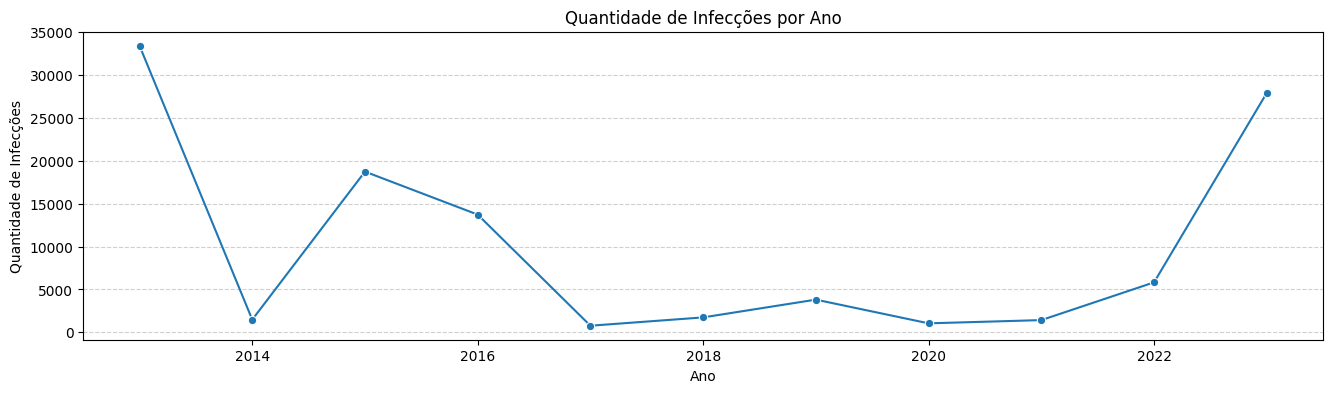

In [ ]:
# criando grafico de linha para visualizar os casos por ano

plt.figure(figsize=(16, 4))
sns.lineplot(data=infeccoes_ano, x='ano', y='qtd_infeccoes', marker='o')
plt.title('Quantidade de Infecções por Ano')
plt.xlabel('Ano')
plt.ylabel('Quantidade de Infecções')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

Fica evidente que a maioria dos casos foram em 2013 e 2023, com uma queda brusca em 2014 e entre 2017-2021. Vale as perguntas:
- Porque houve uma queda tão grande entre 2013 e 2014 (de ~ 34K casos para menos de 2 mil casos)?
- Porque depois de uma queda tão grande, os casos aumentaram drasticamente em 2015?
- Porque entre 2015 e 2022, houve uma baixa dos casos no RJ e em 2023 os casos voltaram à um pico tão grande?

Vale avaliar esses pontos para saber quais possíveis causas dessa variação.

In [ ]:
# criando coluna de mês
df_consolidado_rj['mes'] = df_consolidado_rj['data_infeccoes'].dt.month
df_consolidado_rj.head()

/tmp/ipykernel_1748/1702453458.py:2: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



,municipio,uf,data_infeccoes,qtd_infeccoes,ano,populacao,mes
418440,ANGRA DOS REIS,RJ,2013-01-01,28,2013,181486,1
418441,ANGRA DOS REIS,RJ,2013-02-01,114,2013,181486,2
418442,ANGRA DOS REIS,RJ,2013-03-01,141,2013,181486,3
418443,ANGRA DOS REIS,RJ,2013-04-01,65,2013,181486,4
418444,ANGRA DOS REIS,RJ,2013-05-01,39,2013,181486,5


In [ ]:
# verificando os casos por ano e mês
infeccoes_mes = df_consolidado_rj.groupby(['ano', 'mes'])['qtd_infeccoes'].sum().reset_index().sort_values(by='ano', ascending=True)
infeccoes_mes

,ano,mes,qtd_infeccoes
0,2013,1,2953
1,2013,2,5001
2,2013,3,9803
3,2013,4,8648
4,2013,5,4881
...,...,...,...
127,2023,8,1372
128,2023,9,691
129,2023,10,908
130,2023,11,1855


In [ ]:
# Criando gráfico interativo de linhas por ano e mês usando Plotly Express
# Convertemos a coluna 'ano' para string para que ela seja tratada como categoria discreta (evitando uma escala contínua)
infeccoes_mes['ano'] = infeccoes_mes['ano'].astype(str)

fig = px.line(
    infeccoes_mes,
    x='mes',
    y='qtd_infeccoes',
    color='ano',
    markers=True,
    title='Quantidade de Infecções por Mês e Ano (RJ)',
    labels={'mes': 'Mês', 'qtd_infeccoes': 'Quantidade de Infecções', 'ano': 'Ano'}
)

# Ajustes de layout para garantir que todos os meses (1 a 12) sejam marcados no eixo X
fig.update_layout(
    xaxis=dict(tickmode='array', tickvals=list(range(1, 13))),
    hovermode='x unified'
)

fig.show()

Na maioria dos anos, teve uma tendência clara de aumento nos casos entre os meses de março e maio. Ou seja, independente se os casos caíram ou aumentaram drasticamente, os meses que contém a maior parte dos casos de infecção são nos meses de março, abril e maio. Vale estudar se algo em específico aconteceu ou acontece entre esses meses.

In [ ]:
# 1. Agrupar os dados por município e ano para obter a soma anual de infecções e a população daquele ano
df_taxa_ano = df_consolidado_rj.groupby(['municipio', 'ano']).agg(
    qtd_infeccoes=('qtd_infeccoes', 'sum'),
    populacao=('populacao', 'first')
).reset_index()

# 2. Calcular a taxa de infecção anual (%) para cada município
df_taxa_ano['taxa_infeccao_pct'] = (df_taxa_ano['qtd_infeccoes'] / df_taxa_ano['populacao']) * 100

# 3. Identificar os 5 municípios com as maiores taxas médias de infecção para filtrar o gráfico (evita poluição visual)
top_5_municipios = df_taxa_ano.groupby('municipio')['taxa_infeccao_pct'].mean().nlargest(5).index
df_filtrado = df_taxa_ano[df_taxa_ano['municipio'].isin(top_5_municipios)]

# 4. Criar o gráfico interativo de linhas usando Plotly
fig = px.line(
    df_filtrado,
    x='ano',
    y='taxa_infeccao_pct',
    color='municipio',
    markers=True,
    title='Evolução da Taxa de Infecção Anual (%) - Top 5 Municípios do RJ',
    labels={'ano': 'Ano', 'taxa_infeccao_pct': 'Taxa de Infecção (%)', 'municipio': 'Município'}
)

fig.update_layout(
    xaxis=dict(tickmode='linear', tick0=2013, dtick=1),
    hovermode='x unified'
)

fig.show()

1. O Surto Histórico de Porciúncula (2023):

O gráfico revela que Porciúncula atingiu o maior pico de toda a série histórica em 2023, com a taxa de infecção ultrapassando a barreira dos 5% da sua população infectada em um único ano. Isso indica um surto de proporções críticas que provavelmente sobrecarregou o sistema de saúde local.

2. Epidemias Cíclicas e Alternadas (Dentes de Serra):

Os municípios não acompanham um crescimento constante, mas sim surtos severos e isolados. Por exemplo, Italva teve seu maior pico em 2015 (~4,3%), enquanto Natividade e Porciúncula compartilham um comportamento epidêmico muito similar e simultâneo, com picos alarmantes em 2016 e novamente em 2023.


3. O Período de Calmaria Uniforme (2017 - 2021):

Praticamente todas as 5 cidades do topo mantiveram suas taxas muito próximas de zero durante esse período de 5 anos. Isso aponta para uma fase epidemiológica estável ou para a subnotificação que ocorreu no auge da pandemia de COVID-19 (2020 e 2021), quando os recursos e diagnósticos estavam focados em outra crise.


4. Imunidade de Rebanho Temporária:

Observe que logo após um ano de pico extremo (como o de Natividade em 2016), a taxa despenca quase a zero no ano seguinte (2017). Esse padrão é típico de vírus sazonais: uma vez que grande parte da população local é infectada, a quantidade de pessoas suscetíveis diminui drasticamente até a introdução de um novo sorotipo.

### Verificando distribuições nos dados

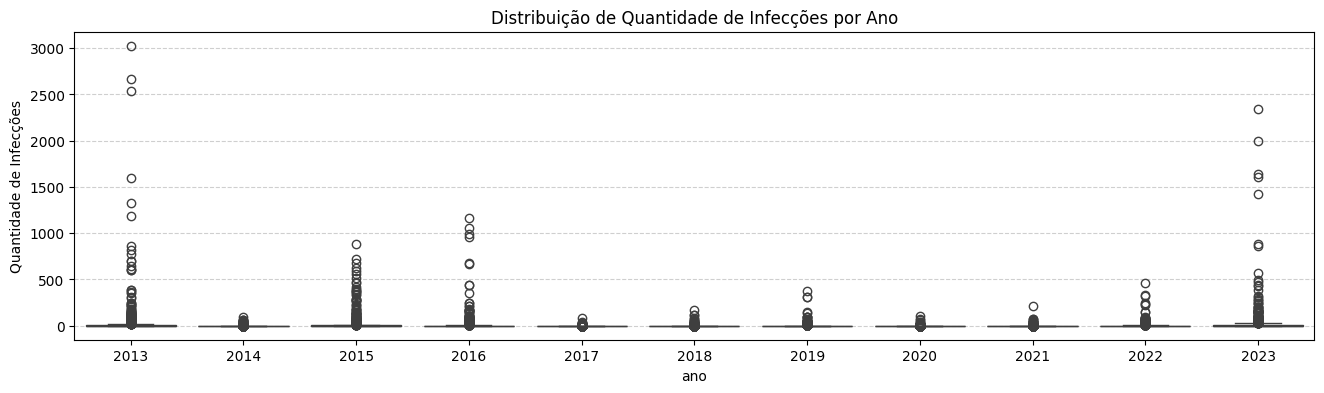

In [ ]:
plt.figure(figsize=(16, 4))
sns.boxplot(data=df_consolidado_rj, x='ano', y='qtd_infeccoes')
plt.title('Distribuição de Quantidade de Infecções por Ano')
plt.ylabel('Quantidade de Infecções')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

### Análise do Boxplot: Distribuição de Quantidade de Infecções por Ano

Ao observar o comportamento das distribuições e dispersões anuais através dos diagramas de caixa (boxplot), podemos extrair conclusões epidemiológicas cruciais:

1. **Presença Massiva de Outliers (Pontos Fora da Curva):**
   - A caixa de quase todos os anos está extremamente achatada próxima ao zero, enquanto vemos diversos pontos isolados (círculos) subindo verticalmente.
   - Isso indica que a imensa maioria dos municípios do Rio de Janeiro registra pouquíssimos casos de dengue na maior parte do tempo. No entanto, em quase todos os anos, existem **municípios específicos que enfrentam surtos isolados devastadores** (representados por esses pontos altos ou *outliers*).

2. **Os Anos de Epidemia Generalizada (2013 e 2023):**
   - **2013** e **2023** não apenas têm os maiores volumes de casos acumulados, mas também apresentam os *outliers* mais extremos (com municípios registrando picos acima de 2.000 e 3.000 infecções em um único mês/período).
   - A dispersão dos pontos em 2023 mostra que o surto não foi apenas forte, mas afetou de forma muito severa múltiplos municípios simultaneamente.

3. **Assimetria Extrema dos Dados:**
   - Como a mediana (linha central da caixa) de quase todos os anos está colada na base zero, conclui-se que a distribuição de infecções de dengue por município é altamente assimétrica à direita.
   - Isso reforça que o combate à dengue precisa ser estratégico: enquanto a maior parte do estado tem uma situação sob controle, focar recursos de saúde pública de forma rápida e localizada nos municípios identificados como *outliers* é vital para conter as epidemias antes que se espalhem.

# **Relatório de Diagnóstico e Recomendações: Epidemias de Dengue no Estado do Rio de Janeiro**

Com base na análise temporal, demográfica e na distribuição espacial dos dados de infecção de dengue entre **2013 e 2023**, consolidamos os seguintes padrões, tendências e propostas de ação.

---

## 1. Principais Padrões Identificados
* **A Ilusão dos Números Absolutos vs. Proporcionais:**
  * Embora a capital (**Rio de Janeiro**) lidere em números absolutos (~34.800 casos), sua imensa população dilui a gravidade do surto (taxa de infecção de **0,53%**).
  * Cidades menores como **Nova Friburgo** (taxa de **3,36%**) e **Campos dos Goytacazes** (taxa de **2,80%**) representam os verdadeiros pontos críticos de atenção epidemiológica do estado.
* **Sazonalidade Estrita e Previsível:**
  * Independentemente do ano ser de alta ou baixa transmissão, há uma concentração massiva e consistente de casos nos meses de **março, abril e maio**.
* **Comportamento Cíclico e em "Dentes de Serra":**
  * Os dados mostram que os surtos não são lineares. Grandes epidemias (como em 2013, 2015 e 2023) são seguidas por quedas bruscas no ano subsequente, devido ao esgotamento de pessoas suscetíveis a um sorotipo viral específico (imunidade coletiva temporária).

---

## 2. Tendências e Possíveis Causas de Surtos
* **A Retomada Explosiva de 2023:**
  * Após um "silêncio epidemiológico" entre 2017 e 2021 (que pode ter sido acentuado pela subnotificação e foco prioritário na COVID-19), 2023 apresentou uma alta simultânea e acentuada em quase todos os municípios do Top 10.
  * **Causas prováveis:** Introdução de novos sorotipos virais para os quais a população não tinha anticorpos, somada a fatores climáticos extremos (como o fenômeno *El Niño*, que eleva temperaturas e altera o regime de chuvas, acelerando o ciclo de reprodução do mosquito *Aedes aegypti*).
* **Vulnerabilidades Regionais Recorrentes:**
  * Municípios como Campos dos Goytacazes mostram picos constantes e crônicos em diferentes décadas (2013 e 2023), sinalizando problemas estruturais de saneamento, abastecimento de água ou características geográficas que favorecem a proliferação contínua do vetor.

---

## 3. Propostas de Soluções e Ações Governamentais

### **Ação I: Planejamento Preventivo Sazonal Antecipado**
* **Janela Crítica de Atuação:** As campanhas de conscientização, eliminação de focos e aplicação de larvicidas não devem começar no verão. Elas precisam ser intensificadas nos meses de **novembro a janeiro**.
* **Objetivo:** Reduzir a população inicial de mosquitos antes do início do pico sazonal previsto para março.

### **Ação II: Alocação de Recursos por Taxa de Incidência (Proporcional)**
* **Redirecionamento de Verbas:** O governo do estado deve distribuir recursos hospitalares, equipes de agentes de saúde e insumos de pulverização (fumacê) prioritariamente com base na **taxa de incidência por 100 mil habitantes**, e não apenas pela população total.
* **Foco:** Cidades de médio e pequeno porte que historicamente operam no limite da capacidade de leitos e enfrentam surtos rápidos (como a região Serrana e Norte Fluminense).

### **Ação III: Monitoramento Genômico de Sorotipos**
* **Prevenção de Picos:** Implementar testes de triagem viral contínuos para identificar precocemente a entrada de novos sorotipos (DENV-3 ou DENV-4, por exemplo) em municípios polo.
* **Impacto:** Permite prever com até um ano de antecedência se o próximo ciclo será de caráter epidêmico grave devido à falta de imunidade da população local.